# UPI & Digital Payments Analytics — DSP Project
### Part 1: Data Understanding → Preprocessing → Cleaning → Features → Outliers → Visualization

**Goal of this notebook:** take the dataset workbook, clean it step by step, and produce the charts that will later go into your Streamlit dashboard.

**Pipeline (each step has its own section below):**

| Step | What we do | Why |
|---|---|---|
| 0 | Setup & load data | Get all sheets into pandas |
| 1 | Understand the data | Never clean blindly — look first |
| 2 | Preprocessing & cleaning | Fix dates, names, text numbers, validate |
| 3 | Missing values & duplicates | Decide what to do with gaps |
| 4 | Feature engineering | Create growth, ticket size, shares, etc. |
| 5 | Outlier detection | Find unusual values — investigate, don't blindly delete |
| 6 | Visualization (EDA) | Charts that answer the research questions |
| 7 | Save clean data | Input for the dashboard step |

**How to run:** put this notebook in the same folder as `UPI_Digital_Payments_Dataset.xlsx`, then run cells top to bottom.
Libraries needed: `pandas numpy matplotlib seaborn openpyxl`.

**Research questions we want to answer (every chart connects to one):**
1. How did UPI volume and value change over time?
2. How fast is UPI growing (month-on-month, year-on-year)?
3. How did the average transaction amount change?
4. Are there seasonal patterns or unusual spikes/drops?
5. Is UPI growth linked to more banks joining?
6. How did merchant payments (P2M) grow compared with person-to-person (P2P)?
7. Which banks have higher decline rates (NFS / AEPS), and are declines business or technical?
8. How do FASTag banks compare in approval rates?

> **Important scope note:** the bank-level files are **NFS/AEPS and FASTag, not UPI**. Always label those charts correctly.

## Step 0 — Setup & load data

**What this does:** imports libraries, sets chart style, creates two folders (`figures/` for charts, `clean_data/` for cleaned files), and reads every sheet of the workbook into a Python dictionary.

**Why a dictionary?** `pd.read_excel(..., sheet_name=None)` returns `{sheet_name: DataFrame}`, so we can access any sheet by name.

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_FILE = "UPI_Digital_Payments_Dataset.xlsx"
FIG_DIR = Path("figures");    FIG_DIR.mkdir(exist_ok=True)
CLEAN_DIR = Path("clean_data"); CLEAN_DIR.mkdir(exist_ok=True)

raw = pd.read_excel(DATA_FILE, sheet_name=None)   # {sheet name: DataFrame}
print("Sheets loaded:", list(raw.keys()))

def save_fig(name):
    # helper: saves the current chart into figures/ so the dashboard step can reuse it
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

Sheets loaded: ['UPI_Master', 'UPI_Monthly', 'Banks_Live', 'P2P_P2M', 'NFS_AEPS', 'FASTag_Acquirer', 'FASTag_Issuer', 'UPI_2026_27']


## Step 1 — Understand the data (before touching it)

**What we check for every sheet:** shape (rows × columns), first rows, data types.

**What to look for:**
- Are dates stored as real dates or as text? (text → must convert)
- Are numbers stored as numbers or text?
- Do column names tell us the real meaning? (we'll see some are misleading)

In [2]:
for name, df in raw.items():
    print("=" * 95)
    print(f"{name}  ->  {df.shape[0]} rows x {df.shape[1]} columns")
    display(df.head(3))
    print(df.dtypes.to_string())

UPI_Master  ->  126 rows x 12 columns


,month,period_raw,upi_volume_mn,upi_value_cr,avg_daily_volume_mn,avg_daily_value_cr,p2pp2m_total_vol,p2pp2m_total_val,p2p_vol,p2p_val,p2m_vol,p2m_val
0,2016-04-01,Apr 2016,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-05-01,May 2016,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-06-01,Jun 2016,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


month                      str
period_raw                 str
upi_volume_mn          float64
upi_value_cr           float64
avg_daily_volume_mn    float64
avg_daily_value_cr     float64
p2pp2m_total_vol       float64
p2pp2m_total_val       float64
p2p_vol                float64
p2p_val                float64
p2m_vol                float64
p2m_val                float64
UPI_Monthly  ->  504 rows x 4 columns


,Series,Period,Value,Unit
0,UPI Value,Apr 2016,0.0,₹ crore
1,UPI Value,May 2016,0.0,₹ crore
2,UPI Value,Jun 2016,0.0,₹ crore


Series        str
Period        str
Value     float64
Unit          str
Banks_Live  ->  89 rows x 5 columns


,id,date,num_of_banks_live_on_upi,volume,value
0,0,2023-01-08,484,10586.02,1576536.56
1,1,2023-01-07,473,9964.61,1533645.20
2,2,2023-01-06,458,9335.06,1475464.27


... (7 outputs left out)

,id,month,issuer_bank,transaction_volume,approved_percent,deemed_approved_percent
0,0,2022-01-06,ICICI Bank,69.95,98.34,1.66
1,1,2022-01-06,IDFC Bank,63.09,98.71,1.29
2,2,2022-01-06,PAYTM Bank,60.86,98.56,1.44


id                           int64
month                          str
issuer_bank                    str
transaction_volume         float64
approved_percent           float64
deemed_approved_percent    float64
UPI_2026_27  ->  6 rows x 4 columns


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,September-2026,756,"24,068.38","29,37,396.67"
1,August-2026,752,"24,508.96","29,82,355.95"
2,July-2026,741,"23,658.35","29,87,880.49"


Month                         str
No. of Banks live on UPI    int64
Volume (In Mn.)               str
Value (In Cr.)                str


**Observations you should note down for your report:**
- `month` / `date` columns are **text** in most sheets → need conversion to real datetime.
- In the `Banks_Live`, `NFS_AEPS` and `FASTag_Issuer` sheets the dates look like `2023-01-08` — that is **YYYY-DD-MM** (so it means **August 2023**). If we parse them normally, every date is wrong.
- In the `NFS_AEPS` sheet, columns named `approved_transaction_volume`, `business_decline_transactions`, `technical_decline_transactions` actually hold **percentages**, not volumes.
- The `UPI_2026_27` sheet holds numbers as **text** with Indian comma style (`29,37,396.67`).

## Step 2 — Preprocessing & cleaning

We clean each dataset separately, because each has different problems. After each fix we **validate** that the fix worked.

### 2.1 Master UPI monthly table (`UPI_Master`)
**Tasks:** convert `month` to datetime, sort by time, check the series is continuous, and validate the numbers against each other.

In [3]:
master = raw["UPI_Master"].copy()
master["month"] = pd.to_datetime(master["month"])          # text -> real date
master = master.sort_values("month").reset_index(drop=True) # chronological order
master = master.drop(columns=["period_raw"])                # redundant text copy of month

# Validation 1: is the monthly series complete (no skipped months)?
expected = pd.date_range(master.month.min(), master.month.max(), freq="MS")
print("Date range:", master.month.min().date(), "->", master.month.max().date(), f"({len(master)} months)")
print("Missing months:", list(expected.difference(master.month)))

# Validation 2: does 'average daily volume' equal volume / days in month?
master["days_in_month"] = master.month.dt.days_in_month
master["avg_daily_volume_calc"] = master.upi_volume_mn / master.days_in_month
diff = (master.avg_daily_volume_calc - master.avg_daily_volume_mn).abs()
print("\nMonths where source daily average differs from our calculation by > 1 Mn/day:")
display(master.loc[diff > 1, ["month", "upi_volume_mn", "avg_daily_volume_mn", "avg_daily_volume_calc"]])

Date range: 2016-04-01 -> 2026-09-01 (126 months)
Missing months: []

Months where source daily average differs from our calculation by > 1 Mn/day:


,month,upi_volume_mn,avg_daily_volume_mn,avg_daily_volume_calc
23,2018-03-01,178.05,7.74,5.743548
37,2019-05-01,733.54,27.44,23.662581


**Reading the result:** the series has no missing months (good). Two months disagree with our own calculation → the source file has small inconsistencies there. We note it as a **data limitation** and use our own calculated daily average (`avg_daily_volume_calc`) for seasonality charts so the number of days in a month doesn't distort the comparison.

**Zeros in 2016:** UPI launched in April 2016, so the first months are genuinely ~0. These are **true zeros, not missing values** — we flag them (`is_ramp_up`) instead of deleting or filling them.

In [4]:
# Flag the launch period (tiny base). Growth % on a near-zero base is meaningless (e.g. +586%).
master["is_ramp_up"] = master.month < "2017-01-01"
print(master.loc[master.is_ramp_up, ["month", "upi_volume_mn", "upi_value_cr"]].to_string(index=False))

     month  upi_volume_mn  upi_value_cr
2016-04-01           0.00          0.00
2016-05-01           0.00          0.00
2016-06-01           0.00          0.00
2016-07-01           0.09          0.38
2016-08-01           0.09          3.09
2016-09-01           0.09         32.64
2016-10-01           0.10         48.57
2016-11-01           0.29        100.46
2016-12-01           1.99        707.93


### 2.2 UPI product statistics (`Banks_Live`) — fixing the wrong date format

**Problem:** dates are `YYYY-DD-MM`. We extract the three parts with a regex and rebuild the date as `YYYY-MM-01`.

**Second problem:** one row (id 61) is labelled with the same date as another row — a typo in the source. Since the file is in strict reverse-chronological order (newest first), we can safely rebuild the correct month sequence and check that **exactly one** row changed.

In [5]:
def fix_dd_mm(s):
    '''Convert text 'YYYY-DD-MM' into a real date (first day of that month).'''
    parts = s.astype(str).str.extract(r"^(\d{4})-(\d{2})-(\d{2})$")   # year, (day-field), (month-field)
    return pd.to_datetime(parts[0] + "-" + parts[2] + "-01")          # year + the real month

ps = raw["Banks_Live"].copy()
ps["month"] = fix_dd_mm(ps["date"])

print("Duplicate months after date fix:")
display(ps[ps.duplicated("month", keep=False)][["id", "date", "month", "volume"]])

# Rows are newest -> oldest by id. Rebuild the expected month sequence and compare.
ps = ps.sort_values("id").reset_index(drop=True)
expected_months = pd.date_range(end=ps.month.max(), periods=len(ps), freq="MS")[::-1]
changed = ps.month.values != expected_months.values
print(f"\nRows whose month was corrected: {changed.sum()}")
display(ps.loc[changed, ["id", "date", "volume"]].assign(corrected_month=expected_months[changed]))
ps["month"] = expected_months

ps = (ps.rename(columns={"num_of_banks_live_on_upi": "banks_live", "volume": "volume_mn", "value": "value_cr"})
        .drop(columns=["id", "date"]).sort_values("month").reset_index(drop=True))
print("\nClean range:", ps.month.min().date(), "->", ps.month.max().date(), "| rows:", len(ps),
      "| continuous:", len(pd.date_range(ps.month.min(), ps.month.max(), freq="MS")) == len(ps))

Duplicate months after date fix:


,id,date,month,volume
60,60,2018-01-08,2018-08-01,312.02
61,61,2018-01-08,2018-08-01,273.75



Rows whose month was corrected: 1


,id,date,volume,corrected_month
61,61,2018-01-08,273.75,2018-07-01



Clean range: 2016-04-01 -> 2023-08-01 | rows: 89 | continuous: True


### 2.3 The 2026-27 Excel sheet (`UPI_2026_27`) — text numbers

**Problem:** numbers are text with commas (`29,37,396.67`), and April has a typo (`29,029,88.05`).
**Fix:** remove commas → convert to float. (Removing commas also repairs the typo because the digits are right, only the comma positions are wrong.)

**Validate:** these values should match the master table exactly. This sheet also gives us *banks live on UPI* for 2026, which extends the banks-live series.

In [6]:
x26 = raw["UPI_2026_27"].copy()
x26.columns = ["month", "banks_live", "volume_mn", "value_cr"]
x26["month"] = pd.to_datetime(x26["month"], format="%B-%Y")        # 'September-2026'
for c in ["banks_live", "volume_mn", "value_cr"]:
    x26[c] = pd.to_numeric(x26[c].astype(str).str.replace(",", "", regex=False))

check = x26.merge(master[["month", "upi_volume_mn", "upi_value_cr"]], on="month")
print("Max volume difference vs master:", (check.volume_mn - check.upi_volume_mn).abs().max())
print("Max value  difference vs master:", (check.value_cr - check.upi_value_cr).abs().max())
display(x26)

Max volume difference vs master: 0.0
Max value  difference vs master: 0.0


,month,banks_live,volume_mn,value_cr
0,2026-09-01,756,24068.38,2937396.67
1,2026-08-01,752,24508.96,2982355.95
2,2026-07-01,741,23658.35,2987880.49
3,2026-06-01,731,22716.07,2892138.67
4,2026-05-01,720,23201.93,2990424.21
5,2026-04-01,713,22346.80,2902988.05


Differences are 0 → the Excel sheet and the master agree, so the master is reliable for 2026.

**Combine banks-live data:** 2016–2023 from `Banks_Live`, and 2026 from `UPI_2026_27`. **Sep 2023 – Mar 2026 has no banks-live data in your files** — that is a real gap, and we keep it as missing (NaN) instead of inventing values.

In [7]:
banks_live = (pd.concat([ps[["month", "banks_live"]], x26[["month", "banks_live"]]])
                .drop_duplicates("month").sort_values("month"))
master = master.merge(banks_live, on="month", how="left")
print("Months with banks_live available:", master.banks_live.notna().sum(), "of", len(master))

Months with banks_live available: 95 of 126


### 2.4 Validate P2P / P2M columns (already inside the master)

Rule that must hold: **P2P + P2M = total** (for both volume and value). We also compare the total with the main UPI series — small differences are expected because different sources revise figures.

In [8]:
has_p2p = master.p2p_vol.notna()
print("P2P+P2M vs their own total  | max volume gap:",
      (master.p2p_vol + master.p2m_vol - master.p2pp2m_total_vol).abs().max().round(3),
      "| max value gap:", (master.p2p_val + master.p2m_val - master.p2pp2m_total_val).abs().max().round(3))
print("P2P/P2M total vs main UPI series | max volume gap:",
      (master.p2pp2m_total_vol - master.upi_volume_mn).abs().max().round(2), "Mn",
      "| max value gap:", (master.p2pp2m_total_val - master.upi_value_cr).abs().max().round(0), "Cr")
print("Months with P2P/P2M data:", has_p2p.sum(), "(", master.loc[has_p2p, 'month'].min().date(), "to", master.loc[has_p2p, 'month'].max().date(), ")")

P2P+P2M vs their own total  | max volume gap: 0.01 | max value gap: 0.01
P2P/P2M total vs main UPI series | max volume gap: 34.88 Mn | max value gap: 8497.0 Cr
Months with P2P/P2M data: 41 ( 2020-04-01 to 2023-08-01 )


Sums match exactly. The small gap vs the main series is a **source revision difference** — for analysis we use the main series for totals and the P2P/P2M columns only for the *share* between P2P and P2M.

### 2.5 Bank name standardization (shared by NFS/AEPS and FASTag sheets)

**Problem:** the same bank appears with many spellings (`Bank Of Baroda` / `Bank of Baroda`, `IDFC` / `IDFC Bank` / `IDFC First Bank`, extra spaces, `Ltd.`, `Limited`, typos like `Finanace`).
If we don't fix this, one bank is counted as 3–4 different banks and every bank-level chart is wrong.

**Method:**
1. Remove extra spaces.
2. Look the lower-cased name up in a mapping dictionary (`NAME_MAP`).
3. If the name isn't in the dictionary, keep it as-is.

> The mergers/renames in the dictionary (e.g. `Purvanchal Gramin Bank` → `Baroda UP Bank`) are based on the names themselves (e.g. "erstwhile ..."). **Verify any merger you rely on in your final analysis** and mention the mapping in your report.

In [9]:
NAME_MAP = {
    # spelling / case / suffix variants
    "bank of baroda": "Bank of Baroda", "bank of india": "Bank of India", "union bank of india": "Union Bank of India",
    "airtel payment bank": "Airtel Payments Bank", "bandhan bank limited": "Bandhan Bank",
    "andhra pradesh grameena vikash bank": "Andhra Pradesh Grameena Vikas Bank",
    "chhattisgarh gramin bank": "Chhattisgarh Rajya Gramin Bank",
    "equitas small finance bank limited": "Equitas Small Finance Bank", "equitas small finance bank ltd.": "Equitas Small Finance Bank",
    "equitas small finance bank": "Equitas Small Finance Bank",
    "fincare small finance bank limited": "Fincare Small Finance Bank",
    "idfc": "IDFC First Bank", "idfc bank": "IDFC First Bank", "idfc first bank ltd": "IDFC First Bank", "idfc first bank": "IDFC First Bank",
    "jana small finance bank ltd": "Jana Small Finance Bank", "jana small finance bank ltd.": "Jana Small Finance Bank",
    "paytm payments bank limited": "Paytm Payments Bank", "paytm payments bank ltd": "Paytm Payments Bank", "paytm bank": "Paytm Payments Bank",
    "punjab and sind bank": "Punjab & Sind Bank",
    "suryoday small finanace bank": "Suryoday Small Finance Bank", "tamilnaad mercantile bank": "Tamilnad Mercantile Bank",
    "the south indian bank": "South Indian Bank", "indusind bank": "IndusInd Bank",
    "yes bank prepaid yp2": "Yes Bank Prepaid YP2", "yes bank - prepaid - yp2": "Yes Bank Prepaid YP2",
    "yes bank ? prepaid ? yp2": "Yes Bank Prepaid YP2", "yes bank ltd": "Yes Bank",
    "axis bank ltd": "Axis Bank", "city union bank limited": "City Union Bank", "fino payment bank": "Fino Payments Bank",
    "kotak bank": "Kotak Mahindra Bank", "kvb bank": "Karur Vysya Bank", "saraswat bank": "Saraswat Co-operative Bank",
    "ujjivan small finance bank limited": "Ujjivan Small Finance Bank",
    # renamed / merged entities (verify before relying on them)
    "dbs bank": "DBS Bank India", "dbs bank india limited": "DBS Bank India", "dbs bank india limited erstwhile lvb": "DBS Bank India",
    "baroda uttar pradesh gramin bank": "Baroda UP Bank", "baroda u.p. bank (erstwhile purvanchal bank)": "Baroda UP Bank",
    "purvanchal gramin bank": "Baroda UP Bank",
    "karnataka gramin bank (erstwhile pragathi krishna gramin bank)": "Karnataka Gramin Bank",
    "karnataka gramin bank erstwhile pragathi krishna gramin bank": "Karnataka Gramin Bank",
    "pragathi krishna gramin bank": "Karnataka Gramin Bank",
    "marudhara gramin bank": "Rajasthan Marudhara Gramin Bank",
}

def clean_bank_name(x):
    x = re.sub(r"\s+", " ", str(x)).strip()       # collapse double spaces, trim ends
    return NAME_MAP.get(x.lower(), x)             # mapped name, or original if not in dictionary

def weighted_group(df, by, pct_cols, w):
    '''Group rows and average percentage columns weighted by volume (a big bank should count more than a tiny one).'''
    tmp = df.copy()
    for c in pct_cols:
        tmp[c] = tmp[c] * tmp[w]
    g = tmp.groupby(by, as_index=False)[[w] + pct_cols].sum()
    for c in pct_cols:
        g[c] = g[c] / g[w]
    return g

### 2.6 NFS / AEPS bank-wise decline data (`NFS_AEPS`)

**Tasks:**
1. Fix the date format (YYYY-DD-MM).
2. Rename misleading columns (they are **percentages**).
3. Standardize bank names, then merge any rows that became duplicates (same bank + product + month) using a volume-weighted average.
4. Check that approved% + business decline% + technical decline% ≈ 100.
5. Check for missing months.

In [10]:
nfs = raw["NFS_AEPS"].copy()
nfs["month"] = fix_dd_mm(nfs["date"])
nfs = nfs.rename(columns={"total_volume": "volume",
                          "approved_transaction_volume": "approved_pct",
                          "business_decline_transactions": "business_decline_pct",
                          "technical_decline_transactions": "technical_decline_pct",
                          "issuer_bank": "bank_raw"})
print("Raw bank names:", nfs.bank_raw.nunique())
nfs["bank"] = nfs.bank_raw.map(clean_bank_name)
print("After standardization:", nfs.bank.nunique())

# Did standardizing create duplicate (product, month, bank) rows?
dups = nfs.duplicated(["product", "month", "bank"], keep=False).sum()
print("Rows that now share the same product+month+bank:", dups)

pct = ["approved_pct", "business_decline_pct", "technical_decline_pct"]
nfs = weighted_group(nfs, ["product", "month", "bank"], pct, "volume")   # merges duplicates (if any)
print("Rows after merging duplicates:", len(nfs))

Raw bank names: 107
After standardization: 83
Rows that now share the same product+month+bank: 12
Rows after merging duplicates: 2294


In [11]:
# Check: do the three percentages add up to ~100?
nfs["pct_sum"] = nfs[pct].sum(axis=1)
nfs["other_pct"] = (100 - nfs.pct_sum).round(2)            # share NOT explained by the 3 columns
print("Typical gap (other_pct) across all rows:")
print(nfs.other_pct.describe().round(2)[["mean", "50%", "max"]].to_string())

nfs["pct_sum_issue"] = nfs.other_pct.abs() > 5             # flag big gaps only (small ~1% gaps are normal)
print("\nRows with a LARGE gap (> 5 percentage points):", nfs.pct_sum_issue.sum(), "of", len(nfs))
display(nfs[nfs.pct_sum_issue].groupby(["product", nfs.month.dt.strftime("%Y-%m")])
        .agg(rows_flagged=("bank", "count"), avg_gap=("other_pct", "mean")).round(1))

# Check: missing months
all_months = pd.date_range(nfs.month.min(), nfs.month.max(), freq="MS")
print("\nMissing months in NFS/AEPS data:", [d.strftime("%b %Y") for d in all_months.difference(nfs.month.unique())])
print("Banks per product-month (should be constant if source gives a fixed top-N):")
print(nfs.groupby(["product", "month"]).size().describe()[["min", "max"]].to_string())

Typical gap (other_pct) across all rows:


mean     1.23
50%      0.84
max     37.26

Rows with a LARGE gap (> 5 percentage points): 55 of 2294


rows_flagged  avg_gap
product month                         
AEPS    2021-09             1      5.8
        2022-07             1      6.7
        2022-08             1      5.3
        2022-09             1      5.2
        2022-12            49     19.3
NFS     2022-11             1      6.2
        2023-03             1      6.2


Missing months in NFS/AEPS data: ['Jun 2023']
Banks per product-month (should be constant if source gives a fixed top-N):
min    49.0
max    50.0


**Reading the result:**
- Bank names reduce a lot after standardization — this is the key cleaning win for this sheet.
- The three percentages usually add up to **about 99%**, not exactly 100 (typical gap ≈ 1 point). That small leftover is a transaction outcome the source doesn't list, plus rounding — normal, no action needed.
- A **large gap (> 5 points)** appears in almost every row of **AEPS Dec 2022** (about 49 banks, average gap ≈ 19 points), plus a few isolated rows. For that month a big part of the transactions isn't covered by the three columns, so rates for that month are less reliable. We keep the rows, keep the flag `pct_sum_issue`, and mention it as a **limitation** — we do not "fix" the numbers.
- One month is missing entirely → we **do not fill it**; line charts will simply show a gap.
- The source only lists a fixed number of banks per month (top banks), so this is **not the complete market**.

### 2.7 FASTag acquirer & issuer data (`FASTag_Acquirer`, `FASTag_Issuer`)

**Tasks:** fix the issuer date format, rename columns to clear names, standardize bank names, and handle impossible values.

**Impossible value:** one acquirer row has approved = 0%, business decline = 0%, technical decline = 0% but still has transactions. That cannot be true — all outcomes can't be zero. It means **data not reported**, so we convert those percentages to `NaN` (missing) instead of keeping fake zeros.

In [12]:
# --- Acquirer ---
acq = raw["FASTag_Acquirer"].copy().drop(columns="id")
acq["month"] = pd.to_datetime(acq["month"])
acq = acq.rename(columns={"acquirer_bank": "bank_raw", "transaction_volume": "volume", "approved_percent": "approved_pct",
                          "bd_percent": "business_decline_pct", "td_percent": "technical_decline_pct"})
acq["bank"] = acq.bank_raw.map(clean_bank_name)
all_zero = (acq[pct].sum(axis=1) == 0)
print("Acquirer rows with all-zero percentages:", all_zero.sum())
acq.loc[all_zero, pct] = np.nan                       # unreported, not a real zero
acq["pct_sum"] = acq[pct].sum(axis=1, min_count=1)

# --- Issuer ---
iss = raw["FASTag_Issuer"].copy().drop(columns="id")
iss["month"] = fix_dd_mm(iss["month"])
iss = iss.rename(columns={"issuer_bank": "bank_raw", "transaction_volume": "volume",
                          "approved_percent": "approved_pct", "deemed_approved_percent": "deemed_approved_pct"})
iss["bank"] = iss.bank_raw.map(clean_bank_name)
iss = weighted_group(iss, ["month", "bank"], ["approved_pct", "deemed_approved_pct"], "volume")

for name, d in [("Acquirer", acq), ("Issuer", iss)]:
    print(f"{name}: {len(d)} rows | {d.bank.nunique()} banks | {d.month.min().date()} -> {d.month.max().date()} | {d.month.nunique()} months")

Acquirer rows with all-zero percentages: 1


Acquirer: 100 rows | 11 banks | 2021-09-01 -> 2022-06-01 | 10 months
Issuer: 273 rows | 29 banks | 2021-09-01 -> 2022-06-01 | 10 months


**What is "deemed approved"?** In FASTag, some transactions are approved automatically ("deemed") when the issuer bank doesn't respond in time. A bank with a **very high deemed-approved %** (like Airtel Payments Bank in this data) is mostly not responding directly — an interesting finding, but remember: this is data, it doesn't prove *why*.

## Step 3 — Missing values & duplicates (final audit)

One summary table across all clean datasets. **Rule we follow:** a missing value is only filled if we have a *justified* reason. Otherwise we leave it as NaN and explain it.

| Missing item | Type | Decision |
|---|---|---|
| P2P/P2M columns outside Apr 2020 – Aug 2023 | Source not covering those months | Leave NaN |
| `banks_live` Sep 2023 – Mar 2026 | No data in provided files | Leave NaN |
| NFS/AEPS: one missing month | Not in source | Leave as gap |
| FASTag acquirer all-zero row | Unreported, fake zeros | Set NaN |

In [13]:
datasets = {"master": master, "nfs_aeps": nfs, "fastag_acquirer": acq, "fastag_issuer": iss, "ps (banks live)": ps}
audit = pd.DataFrame({
    name: {"rows": len(d), "missing cells": int(d.isna().sum().sum()), "duplicate rows": int(d.duplicated().sum())}
    for name, d in datasets.items()
}).T
display(audit)
print("\nMissing values per column in master:")
print(master.isna().sum()[master.isna().sum() > 0].to_string())

,rows,missing cells,duplicate rows
master,126,541,0
nfs_aeps,2294,0,0
fastag_acquirer,100,4,0
fastag_issuer,273,0,0
ps (banks live),89,0,0



Missing values per column in master:
p2pp2m_total_vol    85
p2pp2m_total_val    85
p2p_vol             85
p2p_val             85
p2m_vol             85
p2m_val             85
banks_live          31


## Step 4 — Feature engineering

**What is it?** Creating new, more useful columns from existing ones. Raw volume alone can't tell us "how fast is it growing" or "how big is an average payment".

**Why before outliers?** Outliers in a *growing* series are better found on **growth rates** than on raw levels (a high number in 2026 isn't an outlier — it's just growth).

### 4.1 Features for the UPI master table

| Feature | Formula | Meaning |
|---|---|---|
| `avg_ticket_inr` | value (Cr) × 10⁷ ÷ (volume (Mn) × 10⁶) = value × 10 ÷ volume | Average ₹ per transaction |
| `mom_vol_pct` / `mom_val_pct` | % change vs previous month | Short-term growth |
| `yoy_vol_pct` / `yoy_val_pct` | % change vs same month last year | Growth without seasonality |
| `vol_roll3`, `vol_roll12` | rolling mean of volume | Smooths noise to show the trend |
| `p2m_share_pct` | P2M volume ÷ total P2P+P2M volume × 100 | Share of merchant payments |
| `fy` | Indian financial year (Apr–Mar) | Business-style grouping |
| `year`, `month_num` | from date | For seasonality heatmap |

**Divide-by-zero protection:** early months have 0 volume, so we replace 0 with NaN *before* dividing — otherwise we'd get infinite growth.

In [14]:
m = master.copy()
vol, val = m.upi_volume_mn.replace(0, np.nan), m.upi_value_cr.replace(0, np.nan)

m["avg_ticket_inr"] = (val * 10 / vol)                    # Rs per transaction
m["mom_vol_pct"]  = vol.pct_change() * 100
m["mom_val_pct"]  = val.pct_change() * 100
m["yoy_vol_pct"]  = vol.pct_change(12) * 100
m["yoy_val_pct"]  = val.pct_change(12) * 100
m["vol_roll3"]    = m.upi_volume_mn.rolling(3).mean()
m["vol_roll12"]   = m.upi_volume_mn.rolling(12).mean()
m["p2m_share_pct"] = m.p2m_vol / (m.p2p_vol + m.p2m_vol) * 100
m["year"], m["month_num"] = m.month.dt.year, m.month.dt.month
m["fy"] = np.where(m.month_num >= 4, m.year, m.year - 1)
m["fy"] = "FY" + m.fy.astype(str) + "-" + ((m.fy + 1) % 100).astype(str).str.zfill(2)
m["avg_daily_volume_calc"] = m.upi_volume_mn / m.days_in_month

master = m
display(master[["month", "upi_volume_mn", "avg_ticket_inr", "mom_vol_pct", "yoy_vol_pct", "p2m_share_pct", "fy"]].tail(6).round(2))

,month,upi_volume_mn,avg_ticket_inr,mom_vol_pct,yoy_vol_pct,p2m_share_pct,fy
120,2026-04-01,22346.80,1299.06,-1.30,24.89,NaN,FY2026-27
121,2026-05-01,23201.93,1288.87,3.83,24.22,NaN,FY2026-27
122,2026-06-01,22716.07,1273.17,-2.09,23.49,NaN,FY2026-27
123,2026-07-01,23658.35,1262.93,4.15,21.52,NaN,FY2026-27
124,2026-08-01,24508.96,1216.84,3.60,22.49,NaN,FY2026-27
125,2026-09-01,24068.38,1220.44,-1.80,22.59,NaN,FY2026-27


### 4.2 Features for the bank-level tables

| Feature | Meaning |
|---|---|
| `total_decline_pct` | business decline % + technical decline % |
| `tech_share_of_declines` | what fraction of all declines are technical (fixable by the bank/network) vs business (e.g. insufficient balance) |
| `volume_share_pct` | bank's share of that product-month volume (within the listed banks) |

**Business vs technical decline:** a *business decline* usually has a customer/business reason (e.g. insufficient funds, limits). A *technical decline* is a system/network failure. A bank with high technical declines may need technical investigation — this is exactly the "decision support" use case from your project idea.

In [15]:
nfs["total_decline_pct"] = nfs.business_decline_pct + nfs.technical_decline_pct
nfs["tech_share_of_declines"] = nfs.technical_decline_pct / nfs.total_decline_pct.replace(0, np.nan)
nfs["volume_share_pct"] = nfs.volume / nfs.groupby(["product", "month"]).volume.transform("sum") * 100

acq["total_decline_pct"] = acq.business_decline_pct + acq.technical_decline_pct
display(nfs[["product", "month", "bank", "volume", "approved_pct", "total_decline_pct", "tech_share_of_declines"]].head(5).round(2))

,product,month,bank,volume,approved_pct,total_decline_pct,tech_share_of_declines
0,AEPS,2021-08-01,Airtel Payments Bank,1.33,71.52,25.67,0.32
1,AEPS,2021-08-01,Allahabad Bank,15.18,71.48,25.29,0.42
2,AEPS,2021-08-01,Andhra Pradesh Grameena Vikas Bank,2.18,82.71,14.47,0.22
3,AEPS,2021-08-01,Andhra Pragathi Grameena Bank,1.65,83.14,14.09,0.27
4,AEPS,2021-08-01,Aryavart Bank erstwhile Gramin Bank of Aryavart,2.40,57.26,38.72,0.12


## Step 5 — Outlier detection

**Golden rule:** an outlier is a value to **investigate**, not automatically delete. A sudden drop may be a real event (e.g. COVID lockdown).

**Method — IQR rule:** compute Q1 (25th percentile) and Q3 (75th percentile), IQR = Q3 − Q1. A value is an outlier if it is below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`.
We also compute a **z-score** (how many standard deviations from the average) as a second opinion.

### 5.1 Outliers in UPI monthly growth
We test **month-on-month growth** (not raw volume) and exclude the launch period, where tiny numbers create huge percentages.

In [16]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

g = master.loc[~master.is_ramp_up & master.mom_vol_pct.notna(), ["month", "upi_volume_mn", "mom_vol_pct"]].copy()
lo, hi = iqr_bounds(g.mom_vol_pct)
g["zscore"] = (g.mom_vol_pct - g.mom_vol_pct.mean()) / g.mom_vol_pct.std()
g["is_outlier_growth"] = ~g.mom_vol_pct.between(lo, hi)
print(f"IQR bounds for MoM volume growth: {lo:.1f}% to {hi:.1f}%")
display(g[g.is_outlier_growth].round(2))

master = master.merge(g[["month", "zscore", "is_outlier_growth"]].rename(columns={"zscore": "mom_zscore"}), on="month", how="left")
master["is_outlier_growth"] = master.is_outlier_growth.fillna(False).astype(bool)

IQR bounds for MoM volume growth: -17.3% to 28.2%


,month,upi_volume_mn,mom_vol_pct,zscore,is_outlier_growth
9,2017-01-01,4.46,124.12,5.46,True
11,2017-03-01,6.37,45.43,1.70,True
13,2017-05-01,9.36,30.00,0.97,True
16,2017-08-01,16.80,44.45,1.66,True
17,2017-09-01,30.98,84.40,3.56,True
18,2017-10-01,76.96,148.42,6.62,True
19,2017-11-01,105.02,36.46,1.27,True
20,2017-12-01,145.64,38.68,1.38,True
26,2018-06-01,246.37,30.02,0.97,True
29,2018-09-01,405.87,30.08,0.97,True


**How to interpret:** early-2017/2018 months can be flagged simply because UPI was growing extremely fast from a small base (a *regime* difference, not an error). **Apr 2020** shows a sharp fall — that is the COVID-19 lockdown, a **genuine event**. Decision: **keep all of them**, keep the flag column, and explain each flagged month in your report.

### 5.2 Outliers in bank-level technical decline rates
Here a high technical-decline % is exactly what we want to *find* — it points to banks that deserve a closer look. We run the IQR rule separately for each product (NFS vs AEPS behave differently).

In [17]:
nfs["is_outlier_tech"] = False
for prod, idx in nfs.groupby("product").groups.items():
    lo_p, hi_p = iqr_bounds(nfs.loc[idx, "technical_decline_pct"])
    nfs.loc[idx, "is_outlier_tech"] = ~nfs.loc[idx, "technical_decline_pct"].between(lo_p, hi_p)
    print(f"{prod}: technical decline normal range {lo_p:.2f}% - {hi_p:.2f}%")

print("\nBanks flagged most often (rows flagged):")
display(nfs[nfs.is_outlier_tech].groupby(["product", "bank"]).agg(times_flagged=("month", "count"),
        avg_tech_decline=("technical_decline_pct", "mean"), avg_volume=("volume", "mean")).round(2)
        .sort_values("times_flagged", ascending=False).head(10))

AEPS: technical decline normal range -5.55% - 15.30%
NFS: technical decline normal range -1.96% - 4.28%

Banks flagged most often (rows flagged):


times_flagged  avg_tech_decline  avg_volume
product bank                                                                           
NFS     Andhra Pragathi Grameena Bank                  17             10.66        0.82
AEPS    Tripura Gramin Bank                             9             29.11        0.87
        Bangiya Gramin Vikash Bank                      9             33.84        5.84
NFS     Punjab & Sind Bank                              9              9.73        2.29
AEPS    Punjab & Sind Bank                              8             22.16        1.16
NFS     Andhra Pradesh Grameena Vikas Bank              7              9.22        1.47
        Chhattisgarh Rajya Gramin Bank                  7              6.54        0.77
AEPS    Madhyanchal Gramin Bank                         7             30.97        1.48
NFS     Karur Vysya Bank                                7              5.87        3.94
AEPS    IDFC First Bank                                 6             22.58        0.41

**Decision:** keep these rows. Some of the most-flagged banks are small rural/regional banks with low volume — a small bank's percentage can swing more because it has few transactions. That's why bank charts later are **volume-weighted** and show volume alongside the rate.

## Step 6 — Visualization (EDA)

Every chart answers one research question (stated in its title cell). We use a consistent style and save each chart to `figures/`.

### Chart 1 — UPI volume and value over time *(Q1)*
Two stacked panels with a shared time axis. The dotted line is the **12-month rolling average** (trend). We start from Dec 2016, after the launch ramp.

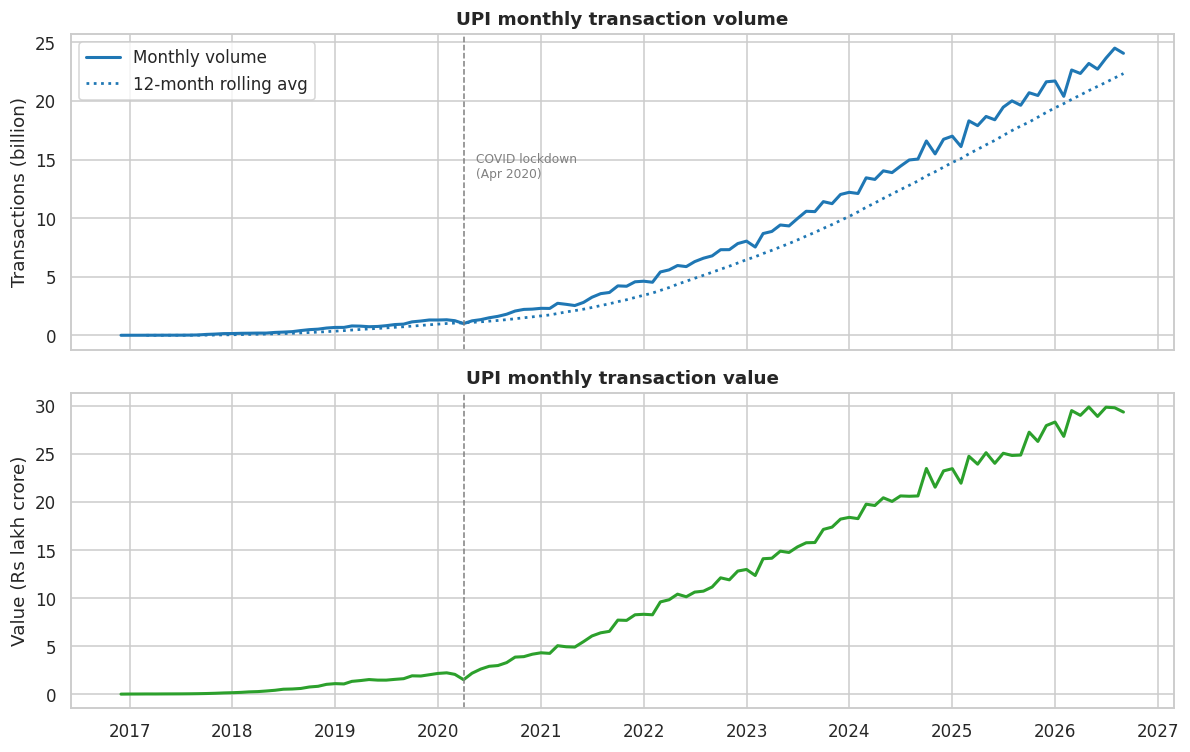

In [18]:
d = master[master.month >= "2016-12-01"]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(d.month, d.upi_volume_mn / 1000, color="#1f77b4", lw=2, label="Monthly volume")
ax[0].plot(d.month, d.vol_roll12 / 1000, color="#1f77b4", ls=":", lw=1.8, label="12-month rolling avg")
ax[0].set_ylabel("Transactions (billion)"); ax[0].set_title("UPI monthly transaction volume"); ax[0].legend()
ax[1].plot(d.month, d.upi_value_cr / 1e5, color="#2ca02c", lw=2)
ax[1].set_ylabel("Value (Rs lakh crore)"); ax[1].set_title("UPI monthly transaction value")
for a in ax:
    a.axvline(pd.Timestamp("2020-04-01"), color="grey", ls="--", lw=1)
ax[0].annotate("COVID lockdown\n(Apr 2020)", (pd.Timestamp("2020-04-01"), d.upi_volume_mn.max()/1000*0.55),
               xytext=(8, 0), textcoords="offset points", fontsize=8, color="grey")
save_fig("01_upi_volume_value")

### Chart 2 — Growth rates *(Q2)*
**YoY growth** compares the same month a year apart, so seasonality cancels out. We start from Apr 2019 because YoY on a tiny 2017–18 base gives huge percentages that would flatten the whole chart.

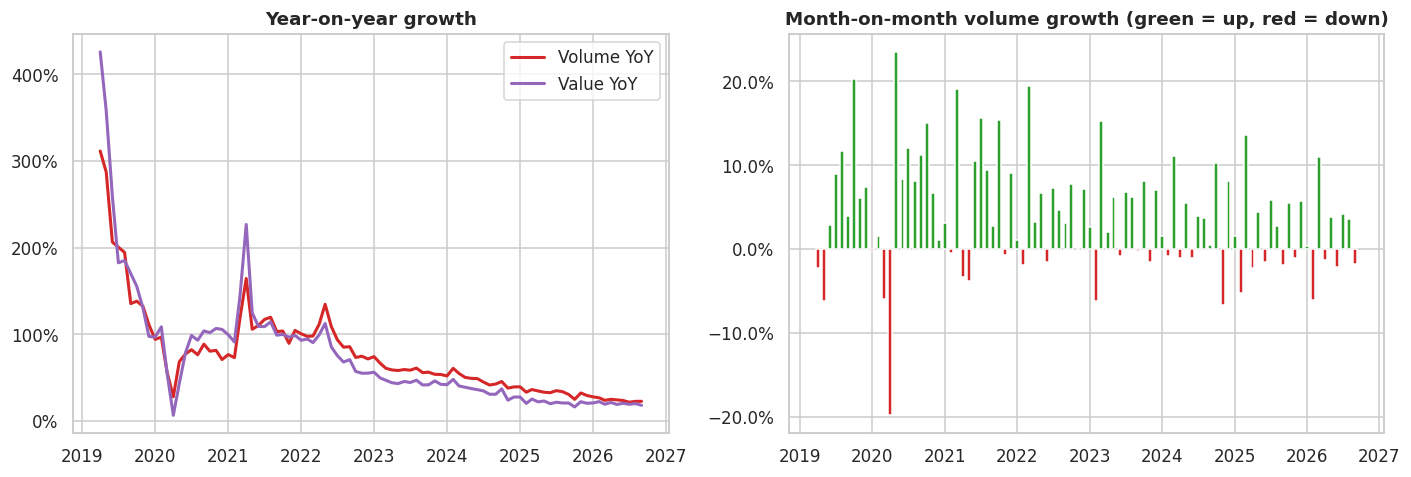

In [19]:
d = master[master.month >= "2019-04-01"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(d.month, d.yoy_vol_pct, color="#d62728", lw=2, label="Volume YoY")
ax[0].plot(d.month, d.yoy_val_pct, color="#9467bd", lw=2, label="Value YoY")
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].set_title("Year-on-year growth"); ax[0].legend()
colors = np.where(d.mom_vol_pct >= 0, "#2ca02c", "#d62728")
ax[1].bar(d.month, d.mom_vol_pct, width=20, color=colors)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].set_title("Month-on-month volume growth (green = up, red = down)")
save_fig("02_growth_rates")

### Chart 3 — Average transaction amount *(Q3)*
Average ticket = value ÷ volume. A falling line means people are using UPI for **smaller everyday payments**; a rising line means larger payments.

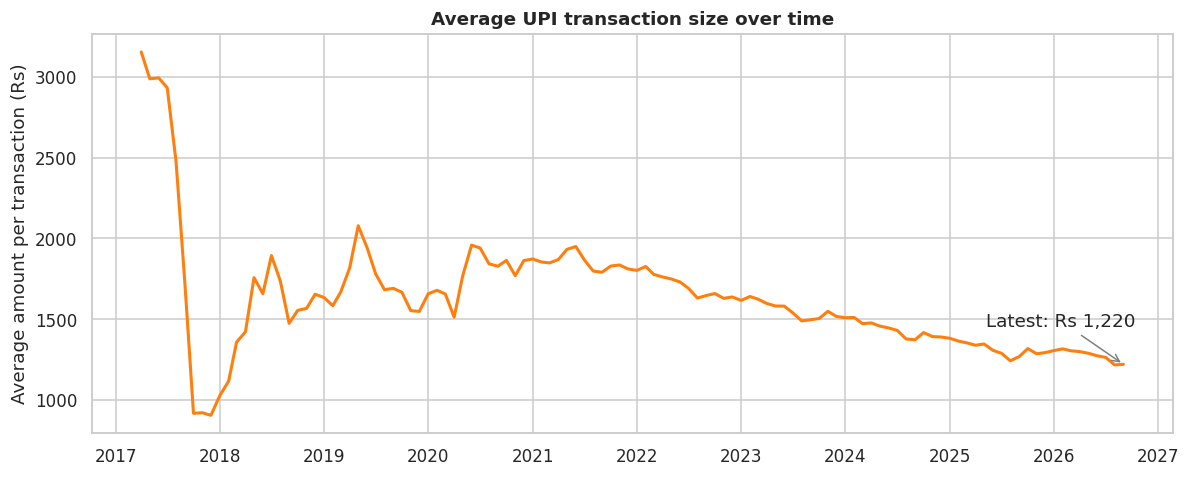

In [20]:
d = master[master.month >= "2017-04-01"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(d.month, d.avg_ticket_inr, color="#ff7f0e", lw=2)
ax.set_ylabel("Average amount per transaction (Rs)"); ax.set_title("Average UPI transaction size over time")
ax.annotate(f"Latest: Rs {d.avg_ticket_inr.iloc[-1]:,.0f}", (d.month.iloc[-1], d.avg_ticket_inr.iloc[-1]),
            xytext=(-90, 25), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="grey"))
save_fig("03_avg_ticket_size")

### Chart 4 — Seasonality heatmap *(Q4)*
Rows = years, columns = calendar months, colour = month-on-month **volume growth**. Repeating dark/light patterns in the same column across years suggest **seasonality** (e.g. festive-season months, February's shorter length). We use the period from 2019 onward.

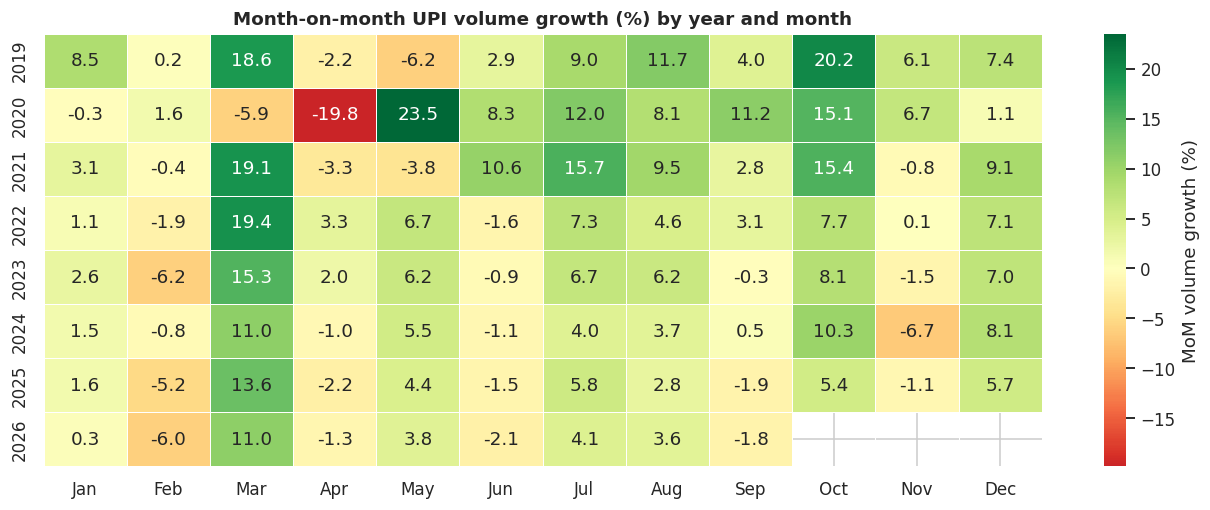

In [21]:
h = master[master.year >= 2019].pivot(index="year", columns="month_num", values="mom_vol_pct")
h.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(h, annot=True, fmt=".1f", cmap="RdYlGn", center=0, linewidths=.5, cbar_kws={"label": "MoM volume growth (%)"}, ax=ax)
ax.set_title("Month-on-month UPI volume growth (%) by year and month"); ax.set_xlabel(""); ax.set_ylabel("")
save_fig("04_seasonality_heatmap")

**What the heatmap shows:** **March** is strongly positive in every year except 2020 (COVID) — typically +11% to +19% — which fits the Indian financial year-end. **February** is weak or negative in most recent years (partly because it has fewer days). **October** (festive season) and **December** are usually strong. Always confirm patterns against your own printed numbers before writing them in the report.

**Tip:** to remove the days-in-month effect you can repeat this heatmap using `avg_daily_volume_calc` instead of total volume.

### Chart 5 — Banks live on UPI vs volume *(Q5)*
More banks live → more people can use UPI. We show both on one chart (two y-axes). Only months where `banks_live` exists are drawn (the Sep 2023 – Mar 2026 gap is real missing data).

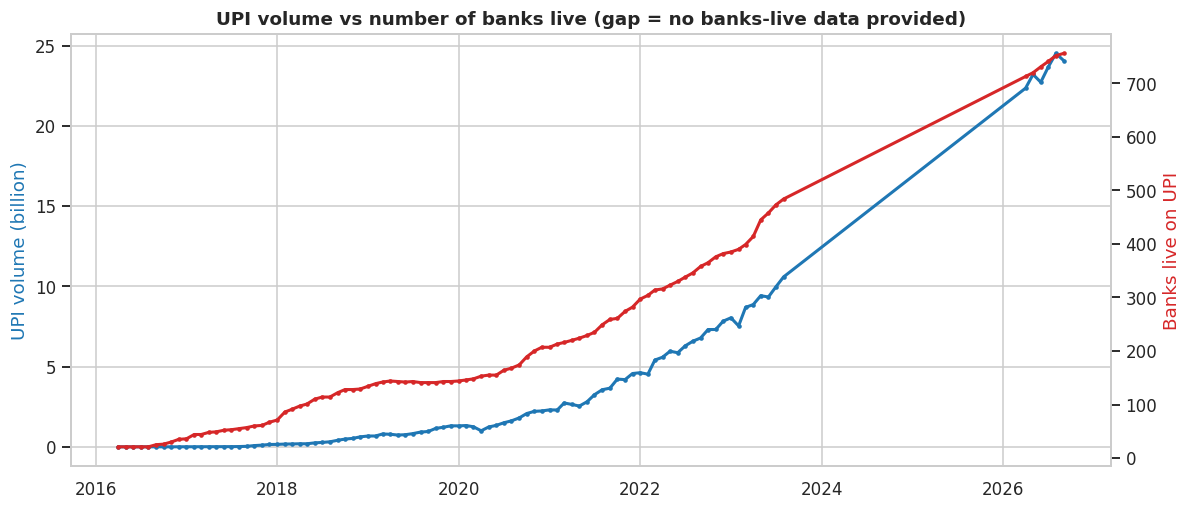

Correlation between volume and banks live: 0.97


In [22]:
d = master[master.banks_live.notna()]
fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax1.plot(d.month, d.upi_volume_mn / 1000, color="#1f77b4", lw=2, marker="o", ms=2, label="Volume (billion)")
ax1.set_ylabel("UPI volume (billion)", color="#1f77b4")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(d.month, d.banks_live, color="#d62728", lw=2, marker="o", ms=2, label="Banks live")
ax2.set_ylabel("Banks live on UPI", color="#d62728")
ax1.set_title("UPI volume vs number of banks live (gap = no banks-live data provided)")
save_fig("05_banks_live_vs_volume")
corr = d[["upi_volume_mn", "banks_live"]].corr().iloc[0, 1]
print(f"Correlation between volume and banks live: {corr:.2f}")

**Careful interpretation:** both lines rise over time, so the correlation is high — but that **does not prove** more banks *caused* more transactions. Both are simply growing with time (adoption, smartphones, merchants). Say "associated with", not "caused by".

### Chart 6 — P2P vs P2M *(Q6)*
Stacked area shows how total volume splits between person-to-person and person-to-merchant payments. The lower panel shows the P2M **share** — a rising share means UPI is becoming more of a shopping/merchant payment system.

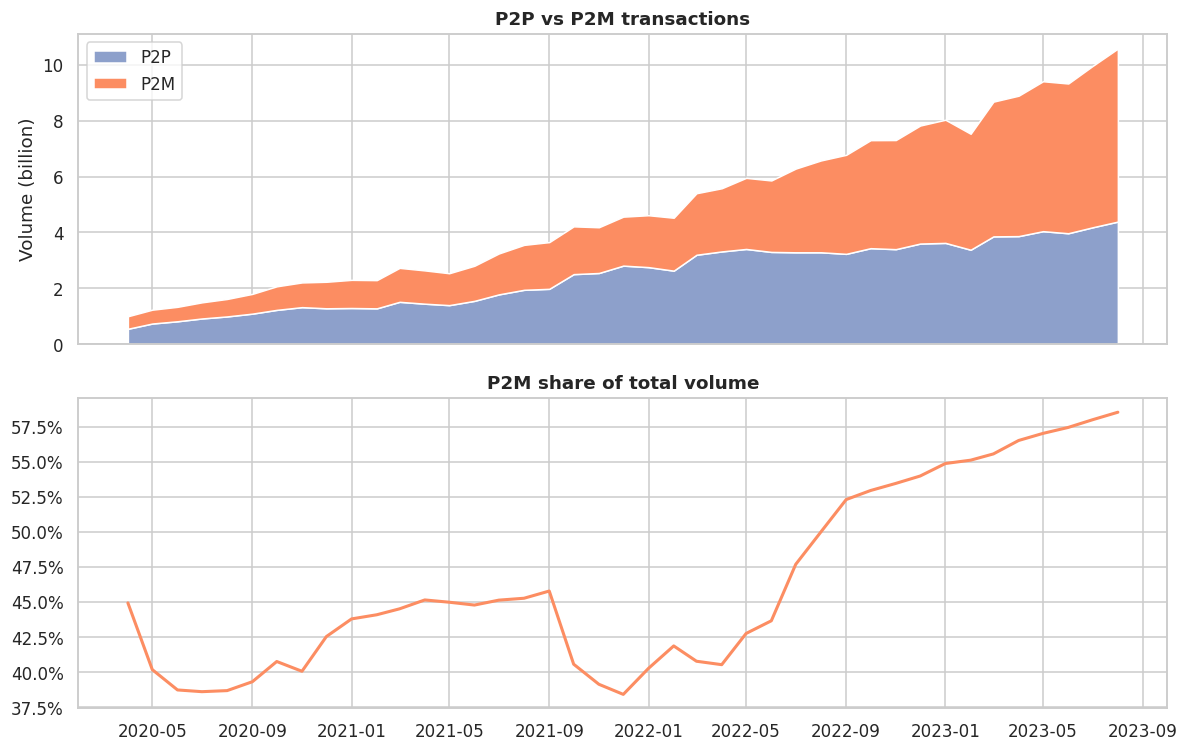

In [23]:
d = master[master.p2p_vol.notna()]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].stackplot(d.month, d.p2p_vol / 1000, d.p2m_vol / 1000, labels=["P2P", "P2M"], colors=["#8da0cb", "#fc8d62"])
ax[0].set_ylabel("Volume (billion)"); ax[0].set_title("P2P vs P2M transactions"); ax[0].legend(loc="upper left")
ax[1].plot(d.month, d.p2m_share_pct, color="#fc8d62", lw=2)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].set_title("P2M share of total volume")
save_fig("06_p2p_vs_p2m")

### Chart 7 — NFS vs AEPS decline rates over time *(Q7)*
**Volume-weighted** monthly decline rates (a big bank counts more than a small one). Lines have a **gap** where a month is missing in the source.

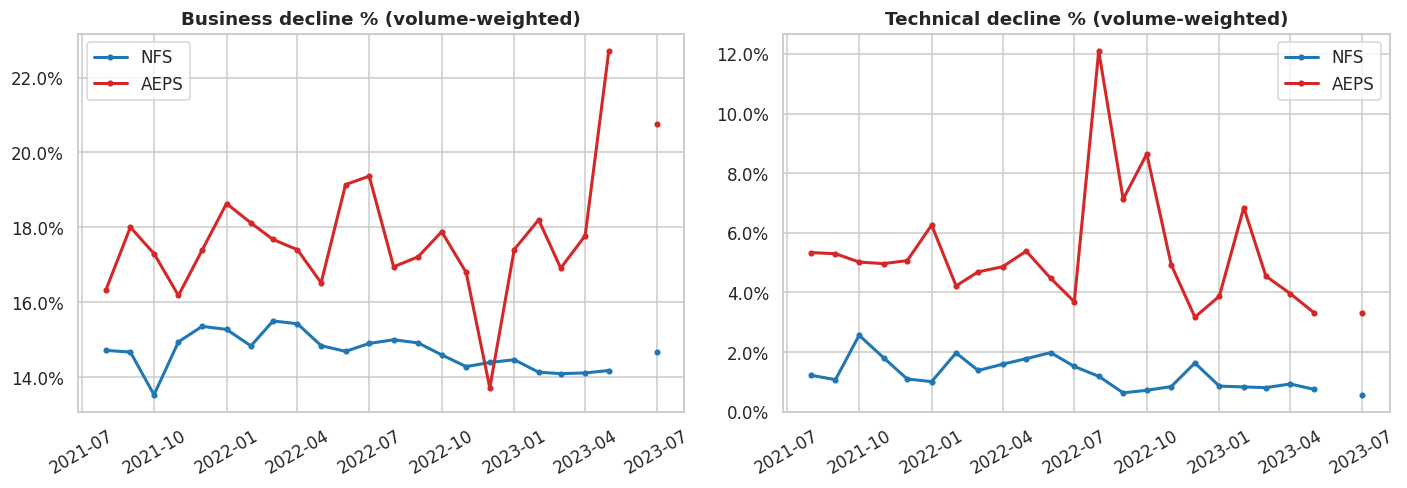

In [24]:
monthly = weighted_group(nfs, ["product", "month"], ["approved_pct", "business_decline_pct", "technical_decline_pct"], "volume")
# reindex to the full calendar so the missing month shows as a gap instead of a straight line
full = pd.date_range(monthly.month.min(), monthly.month.max(), freq="MS")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True)
for prod, col in [("NFS", "#1f77b4"), ("AEPS", "#d62728")]:
    s = monthly[monthly["product"] == prod].set_index("month").reindex(full)
    ax[0].plot(s.index, s.business_decline_pct, color=col, lw=2, marker="o", ms=3, label=prod)
    ax[1].plot(s.index, s.technical_decline_pct, color=col, lw=2, marker="o", ms=3, label=prod)
ax[0].set_title("Business decline % (volume-weighted)"); ax[1].set_title("Technical decline % (volume-weighted)")
for a in ax:
    a.yaxis.set_major_formatter(mtick.PercentFormatter()); a.legend(); a.tick_params(axis="x", rotation=30)
save_fig("07_nfs_aeps_decline_trend")

### Chart 8 — Which banks have high declines? *(Q7)*
For each product we take the **10 largest banks by total volume** and compare their average business vs technical decline %. Comparing large banks avoids being fooled by tiny banks with unstable percentages.

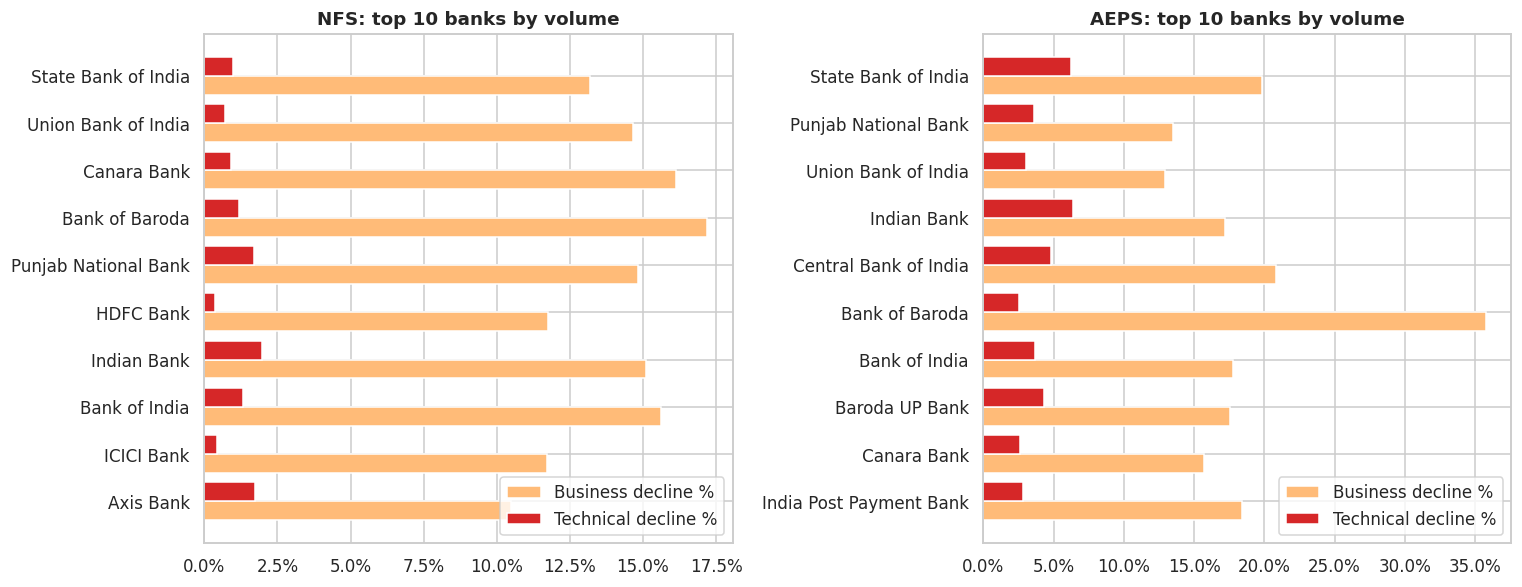

In [25]:
bank_avg = weighted_group(nfs, ["product", "bank"], ["approved_pct", "business_decline_pct", "technical_decline_pct"], "volume")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, prod in zip(ax, ["NFS", "AEPS"]):
    t = bank_avg[bank_avg["product"] == prod].nlargest(10, "volume").sort_values("volume")
    y = np.arange(len(t))
    a.barh(y - 0.2, t.business_decline_pct, height=0.4, label="Business decline %", color="#ffbb78")
    a.barh(y + 0.2, t.technical_decline_pct, height=0.4, label="Technical decline %", color="#d62728")
    a.set_yticks(y); a.set_yticklabels(t.bank); a.set_title(f"{prod}: top 10 banks by volume"); a.legend(loc="lower right")
    a.xaxis.set_major_formatter(mtick.PercentFormatter())
save_fig("08_top_banks_declines")

### Chart 9 — Outliers: technical decline distribution *(Q7)*
A **box plot** shows the middle 50% of values as a box; dots outside the whiskers are the IQR outliers we flagged in Step 5.

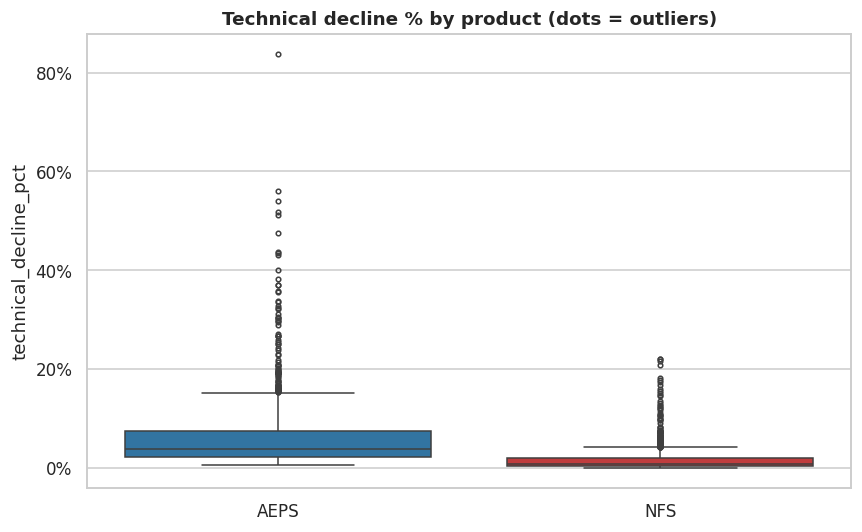

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=nfs, x="product", y="technical_decline_pct", palette=["#1f77b4", "#d62728"], ax=ax, fliersize=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_title("Technical decline % by product (dots = outliers)"); ax.set_xlabel("")
save_fig("09_boxplot_technical_decline")

### Chart 10 — Outlier months in UPI growth *(Q4)*
Same IQR bounds from Step 5.1 drawn on the growth series. Red points are flagged months; the shaded band is the "normal" range.

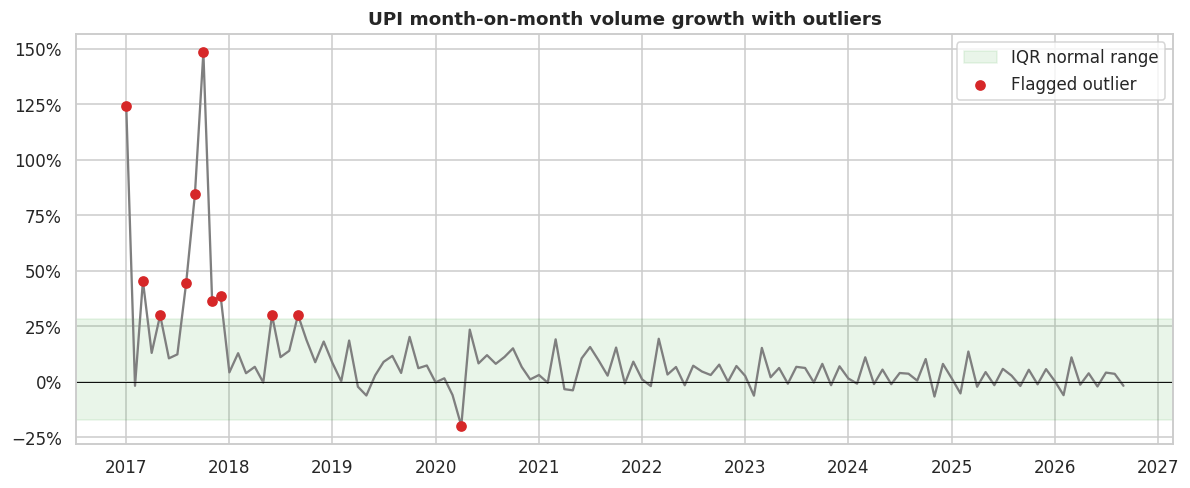

In [27]:
d = master[~master.is_ramp_up & master.mom_vol_pct.notna()]
lo, hi = iqr_bounds(d.mom_vol_pct)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(d.month, d.mom_vol_pct, color="#7f7f7f", lw=1.5)
ax.axhspan(lo, hi, color="#2ca02c", alpha=0.1, label="IQR normal range")
o = d[d.is_outlier_growth]
ax.scatter(o.month, o.mom_vol_pct, color="#d62728", zorder=3, label="Flagged outlier")
ax.axhline(0, color="black", lw=.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_title("UPI month-on-month volume growth with outliers"); ax.legend()
save_fig("10_growth_outliers")

### Chart 11 — FASTag: approval rate by acquirer bank, and deemed-approved by issuer bank *(Q8)*
- **Left (acquirer):** volume-weighted approval % per bank (the bank that collects the toll).
- **Right (issuer):** banks with the highest share of **deemed-approved** transactions (the bank that issued the tag). Only 10 months of FASTag data exist, so treat this as a snapshot. **Note:** the left chart's x-axis starts near 75% (not 0%) so differences are visible — say this in your report, because truncated bar axes can exaggerate gaps.

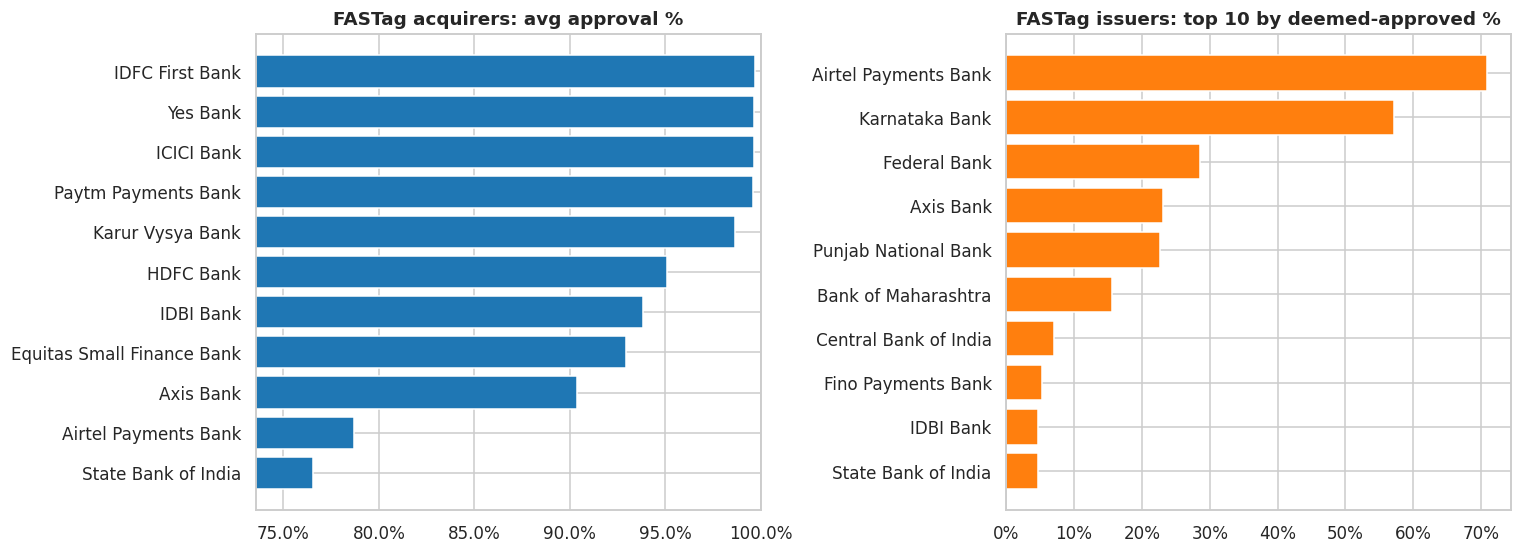

In [28]:
acq_ok = acq.dropna(subset=["approved_pct"])
a_avg = weighted_group(acq_ok, ["bank"], ["approved_pct"], "volume").sort_values("approved_pct")
i_avg = weighted_group(iss, ["bank"], ["deemed_approved_pct"], "volume").nlargest(10, "deemed_approved_pct").sort_values("deemed_approved_pct")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
ax[0].barh(a_avg.bank, a_avg.approved_pct, color="#1f77b4")
ax[0].set_xlim(a_avg.approved_pct.min() - 3, 100); ax[0].set_title("FASTag acquirers: avg approval %")
ax[1].barh(i_avg.bank, i_avg.deemed_approved_pct, color="#ff7f0e")
ax[1].set_title("FASTag issuers: top 10 by deemed-approved %")
for a in ax: a.xaxis.set_major_formatter(mtick.PercentFormatter())
save_fig("11_fastag_banks")

### Chart 12 — Correlation heatmap of engineered UPI features
Correlation shows which numeric columns move together (+1 = move together, −1 = opposite, 0 = no linear relation). Because almost everything trends upward over time, volume, value and banks live will be strongly correlated — **treat this as exploration, not proof of cause**.

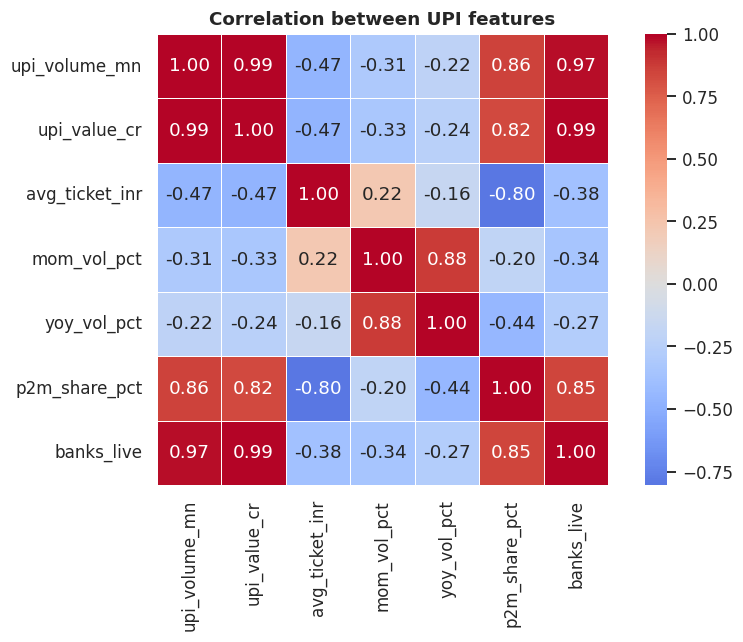

In [29]:
cols = ["upi_volume_mn", "upi_value_cr", "avg_ticket_inr", "mom_vol_pct", "yoy_vol_pct", "p2m_share_pct", "banks_live"]
c = master.loc[master.month >= "2017-01-01", cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5, ax=ax)
ax.set_title("Correlation between UPI features")
save_fig("12_correlation_heatmap")

## Step 7 — Key numbers + save the clean data

**Key numbers** are calculated from the data (never typed by hand) so they stay correct if the data changes. The cleaned CSVs go to `clean_data/` — these are the **input files for the Streamlit dashboard step**.

In [30]:
latest = master.iloc[-1]
base = master[master.month == latest.month - pd.DateOffset(years=5)].iloc[0]     # 5 years earlier (stable base, not the 2016 launch)
cagr = ((latest.upi_volume_mn / base.upi_volume_mn) ** (1 / 5) - 1) * 100

print(f"Latest month           : {latest.month:%b %Y}")
print(f"UPI volume (latest)    : {latest.upi_volume_mn:,.0f} Mn  ({latest.upi_volume_mn/1000:.1f} billion)")
print(f"UPI value (latest)     : Rs {latest.upi_value_cr:,.0f} Cr  (Rs {latest.upi_value_cr/1e5:.1f} lakh crore)")
print(f"YoY volume growth      : {latest.yoy_vol_pct:.1f}%   | YoY value growth: {latest.yoy_val_pct:.1f}%")
print(f"Average ticket (latest): Rs {latest.avg_ticket_inr:,.0f}")
print(f"Volume 5-year CAGR ({base.month:%b %Y} -> {latest.month:%b %Y}): {cagr:.1f}% per year")
pm = master.dropna(subset=["p2m_share_pct"])
print(f"P2M share              : {pm.p2m_share_pct.iloc[0]:.1f}% ({pm.month.iloc[0]:%b %Y}) -> {pm.p2m_share_pct.iloc[-1]:.1f}% ({pm.month.iloc[-1]:%b %Y})")
print(f"Flagged growth outliers: {', '.join(master[master.is_outlier_growth].month.dt.strftime('%b %Y'))}")

Latest month           : Sep 2026
UPI volume (latest)    : 24,068 Mn  (24.1 billion)
UPI value (latest)     : Rs 2,937,397 Cr  (Rs 29.4 lakh crore)
YoY volume growth      : 22.6%   | YoY value growth: 18.0%
Average ticket (latest): Rs 1,220
Volume 5-year CAGR (Sep 2021 -> Sep 2026): 45.8% per year
P2M share              : 44.9% (Apr 2020) -> 58.5% (Aug 2023)
Flagged growth outliers: Jan 2017, Mar 2017, May 2017, Aug 2017, Sep 2017, Oct 2017, Nov 2017, Dec 2017, Jun 2018, Sep 2018, Apr 2020


In [31]:
master.to_csv(CLEAN_DIR / "upi_master_clean.csv", index=False)
nfs.to_csv(CLEAN_DIR / "nfs_aeps_bank_clean.csv", index=False)
acq.to_csv(CLEAN_DIR / "fastag_acquirer_clean.csv", index=False)
iss.to_csv(CLEAN_DIR / "fastag_issuer_clean.csv", index=False)
ps.to_csv(CLEAN_DIR / "upi_banks_live_clean.csv", index=False)

print("Saved clean files:")
for p in sorted(CLEAN_DIR.glob("*.csv")):
    print(" -", p.name, f"({len(pd.read_csv(p))} rows)")
print("Saved charts:", len(list(FIG_DIR.glob('*.png'))))

Saved clean files:
 - fastag_acquirer_clean.csv (100 rows)
 - fastag_issuer_clean.csv (273 rows)
 - nfs_aeps_bank_clean.csv (2294 rows)
 - upi_banks_live_clean.csv (89 rows)
 - upi_master_clean.csv (126 rows)
Saved charts: 12


## What you have now & what comes next

**Done in this notebook:** data understanding → date/format fixes → bank-name standardization → validation → missing-value decisions → feature engineering → outlier flags → 12 charts → clean files saved.

**Limitations to write in your report** (examiners like honest limitations):
1. Bank-wise data is **NFS/AEPS and FASTag, not UPI**; it lists only top banks per month.
2. NFS/AEPS covers Aug 2021 – Jul 2023 with one missing month, and AEPS Dec 2022 where a large share of outcomes is unexplained by the three columns.
3. FASTag has only 10 months.
4. P2P/P2M covers only Apr 2020 – Aug 2023; banks-live has a gap from Sep 2023 to Mar 2026.
5. Aggregate data cannot identify fraud or the exact *cause* of a decline.
6. Bank mergers in the name mapping should be verified.

**Next step — Dashboard:** load the CSVs from `clean_data/` in a Streamlit app and rebuild these charts in Plotly with filters (date range, product, bank).